<a href="https://colab.research.google.com/github/varshneylucky200702-crypto/CleanSlate_project/blob/main/Copy_of_Stock_Price_Forecasting_for_FinSmart_Securities.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stock Price Forecasting for FinSmart Securities

## AI & Generative AI Virtual Internship Project

### Developed using Machine Learning in Google Colab

Prepared By: Syed Junaid

Tools & Technologies:
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

# Step 1: Problem Statement

Stock price prediction is an important task in financial analysis and investment planning. Investors and financial analysts use company information, market conditions, and economic indicators to estimate future stock prices.

The objective of this project is to build a Machine Learning model that predicts the forecast stock price of companies using financial, market, and economic features provided in the dataset. The project also compares multiple regression algorithms and analyzes the factors that influence stock price prediction.

# Step 2: Project Objectives

The objectives of this project are:

- Understand the dataset.
- Perform data preprocessing.
- Explore the dataset using visualizations.
- Engineer useful features.
- Train multiple Machine Learning regression models.
- Compare model performance.
- Predict stock prices.
- Generate meaningful business insights.

In [1]:
# Step 1: Import Required Libraries

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
# Step 2: Load the Dataset

dataset_url = "https://raw.githubusercontent.com/YBIFoundation/MLProjectIdeas/refs/heads/main/Stock%20Price%20Forecasting%20for%20FinSmart%20Securities.csv"

df = pd.read_csv(dataset_url)

In [3]:
# Step 3: Display the First Five Rows

df.head()

,stock_symbol,sector,days_since_listing,avg_trading_volume,pe_ratio,market_sentiment,quarterly_growth_percent,gdp_growth_percent,inflation_rate_percent,recent_news_score,beta_value,forecast_price_inr
0,WIPRO,Banking,2906,586973.0,38.05,0.89,11.91,5.39,4.75,0.42,1.11,204.33
1,TCS,Energy,4866,1243868.0,25.78,-0.68,19.57,6.03,4.91,1.93,0.94,189.90
2,RELIANCE,Infrastructure,3686,1383937.0,12.54,0.48,8.73,8.67,6.18,-1.00,1.03,163.79
3,ICICIBANK,IT,4506,804741.0,17.57,-0.10,15.83,4.55,3.31,0.62,1.17,184.69
4,HDFCBANK,Infrastructure,4620,827764.0,13.57,-0.59,21.42,8.90,7.45,0.40,0.99,184.91


In [4]:
# Step 4: Check the Shape of the Dataset

df.shape

(1000, 12)

# Dataset Understanding

In [5]:
# Step 5: Display Column Names

df.columns

Index(['stock_symbol', 'sector', 'days_since_listing', 'avg_trading_volume',
       'pe_ratio', 'market_sentiment', 'quarterly_growth_percent',
       'gdp_growth_percent', 'inflation_rate_percent', 'recent_news_score',
       'beta_value', 'forecast_price_inr'],
      dtype='object')

In [6]:
# Step 6: Display Dataset Information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   stock_symbol              1000 non-null   object 
 1   sector                    1000 non-null   object 
 2   days_since_listing        1000 non-null   int64  
 3   avg_trading_volume        1000 non-null   float64
 4   pe_ratio                  1000 non-null   float64
 5   market_sentiment          1000 non-null   float64
 6   quarterly_growth_percent  1000 non-null   float64
 7   gdp_growth_percent        1000 non-null   float64
 8   inflation_rate_percent    1000 non-null   float64
 9   recent_news_score         1000 non-null   float64
 10  beta_value                1000 non-null   float64
 11  forecast_price_inr        1000 non-null   float64
dtypes: float64(9), int64(1), object(2)
memory usage: 93.9+ KB


In [7]:
# Step 7: Display Statistical Summary

df.describe()

,days_since_listing,avg_trading_volume,pe_ratio,market_sentiment,quarterly_growth_percent,gdp_growth_percent,inflation_rate_percent,recent_news_score,beta_value,forecast_price_inr
count,1000.000000,1000.000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2464.425000,998617.941,25.253450,0.008950,10.135180,6.019740,5.442140,-0.014010,0.993860,185.357760
std,1464.404609,258631.393,9.590436,0.563343,11.604762,1.724848,1.453446,1.179523,0.201322,35.321493
min,35.000000,100000.000,5.000000,-0.990000,-9.970000,3.010000,3.000000,-1.990000,0.500000,83.680000
25%,1216.750000,815709.000,18.367500,-0.460000,-0.010000,4.537500,4.147500,-1.042500,0.850000,160.530000
50%,2423.500000,1000986.500,25.135000,0.010000,10.195000,6.080000,5.450000,-0.005000,1.000000,184.730000
75%,3768.750000,1182158.000,31.377500,0.500000,20.470000,7.540000,6.730000,1.000000,1.140000,209.902500
max,4995.000000,1819503.000,57.630000,1.000000,29.970000,8.990000,8.000000,1.990000,1.660000,302.620000


# Data Quality Assessment

In [8]:
# Step 8: Check Missing Values

df.isnull().sum()

,0
stock_symbol,0
sector,0
days_since_listing,0
avg_trading_volume,0
pe_ratio,0
market_sentiment,0
quarterly_growth_percent,0
gdp_growth_percent,0
inflation_rate_percent,0
recent_news_score,0


In [9]:
# Step 9: Check Duplicate Rows

df.duplicated().sum()

np.int64(0)

In [10]:
# Step 10: Check Unique Values in Each Column

df.nunique()

,0
stock_symbol,10
sector,5
days_since_listing,916
avg_trading_volume,998
pe_ratio,851
market_sentiment,199
quarterly_growth_percent,871
gdp_growth_percent,486
inflation_rate_percent,437
recent_news_score,366


# Exploratory Data Analysis (EDA)

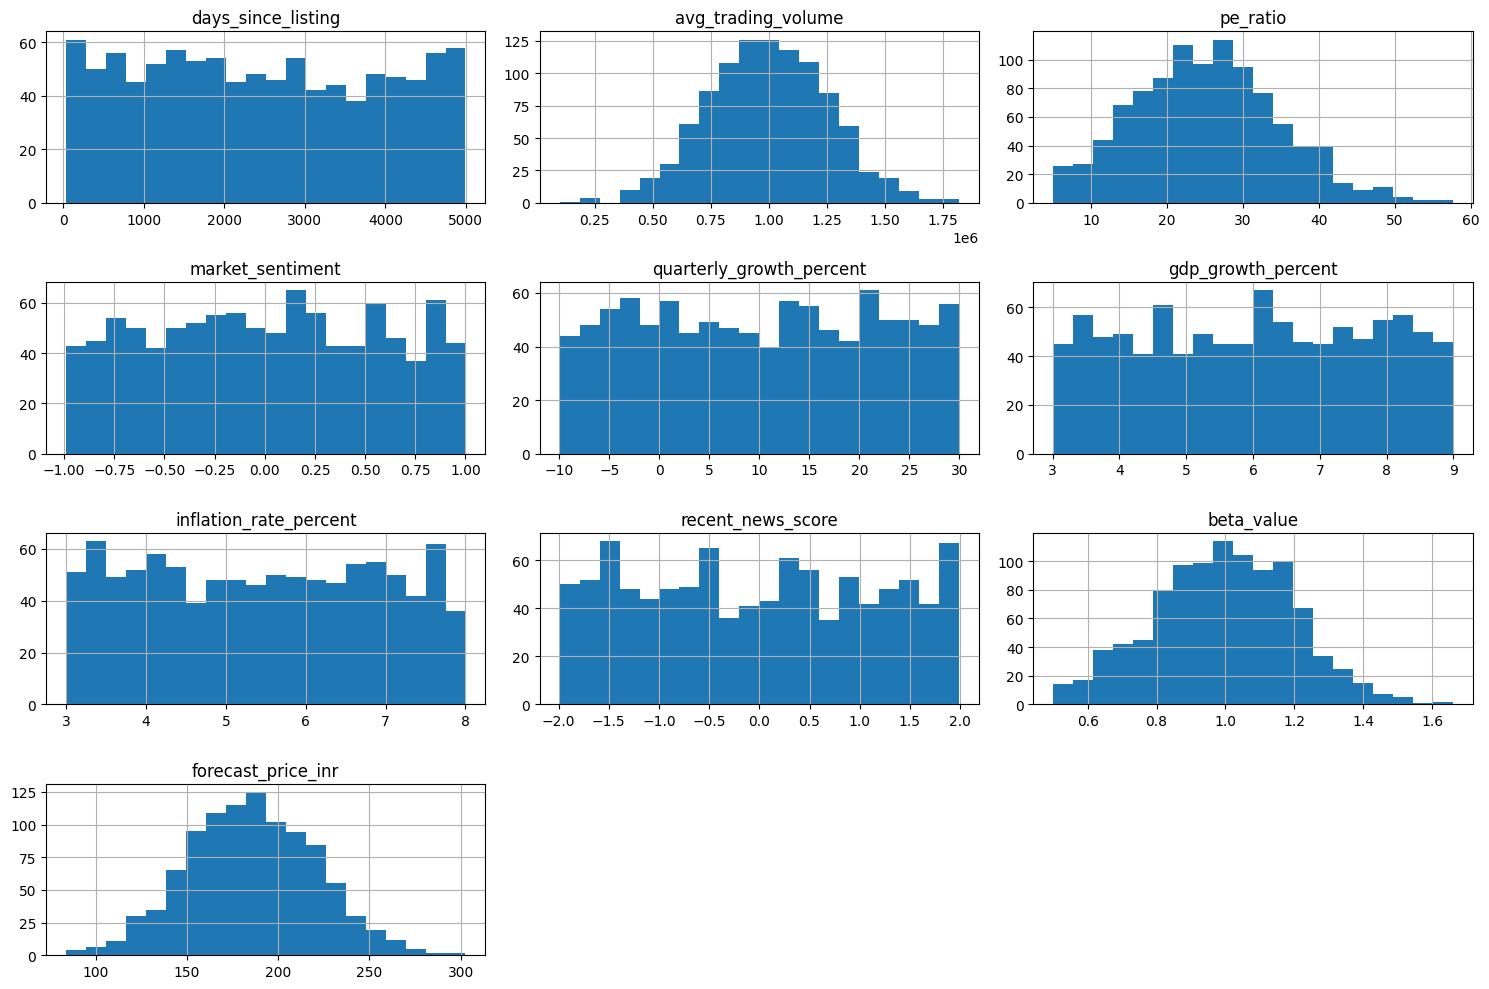

In [11]:
# Step 11: Display the Distribution of Numerical Features

df.hist(figsize=(15, 10), bins=20)

plt.tight_layout()

plt.show()

In [12]:
# Step 12: Correlation Matrix

correlation_matrix = df.corr(numeric_only=True)

correlation_matrix

,days_since_listing,avg_trading_volume,pe_ratio,market_sentiment,quarterly_growth_percent,gdp_growth_percent,inflation_rate_percent,recent_news_score,beta_value,forecast_price_inr
days_since_listing,1.000000,0.011934,-0.018466,0.022451,0.002645,-0.045376,-0.022094,0.006629,0.034706,-0.015238
avg_trading_volume,0.011934,1.000000,-0.043063,-0.021576,0.028273,-0.043644,-0.021159,0.019176,-0.012122,-0.018238
pe_ratio,-0.018466,-0.043063,1.000000,0.029269,-0.023914,0.002860,-0.009561,0.110798,-0.016088,0.418353
market_sentiment,0.022451,-0.021576,0.029269,1.000000,0.020657,0.023552,0.004795,-0.006388,0.027150,0.171632
quarterly_growth_percent,0.002645,0.028273,-0.023914,0.020657,1.000000,0.068444,0.009448,-0.006486,-0.037287,0.634731
gdp_growth_percent,-0.045376,-0.043644,0.002860,0.023552,0.068444,1.000000,-0.011609,-0.002854,-0.043235,0.177002
inflation_rate_percent,-0.022094,-0.021159,-0.009561,0.004795,0.009448,-0.011609,1.000000,-0.010038,-0.070176,-0.096825
recent_news_score,0.006629,0.019176,0.110798,-0.006388,-0.006486,-0.002854,-0.010038,1.000000,0.001930,0.186356
beta_value,0.034706,-0.012122,-0.016088,0.027150,-0.037287,-0.043235,-0.070176,0.001930,1.000000,0.110874
forecast_price_inr,-0.015238,-0.018238,0.418353,0.171632,0.634731,0.177002,-0.096825,0.186356,0.110874,1.000000


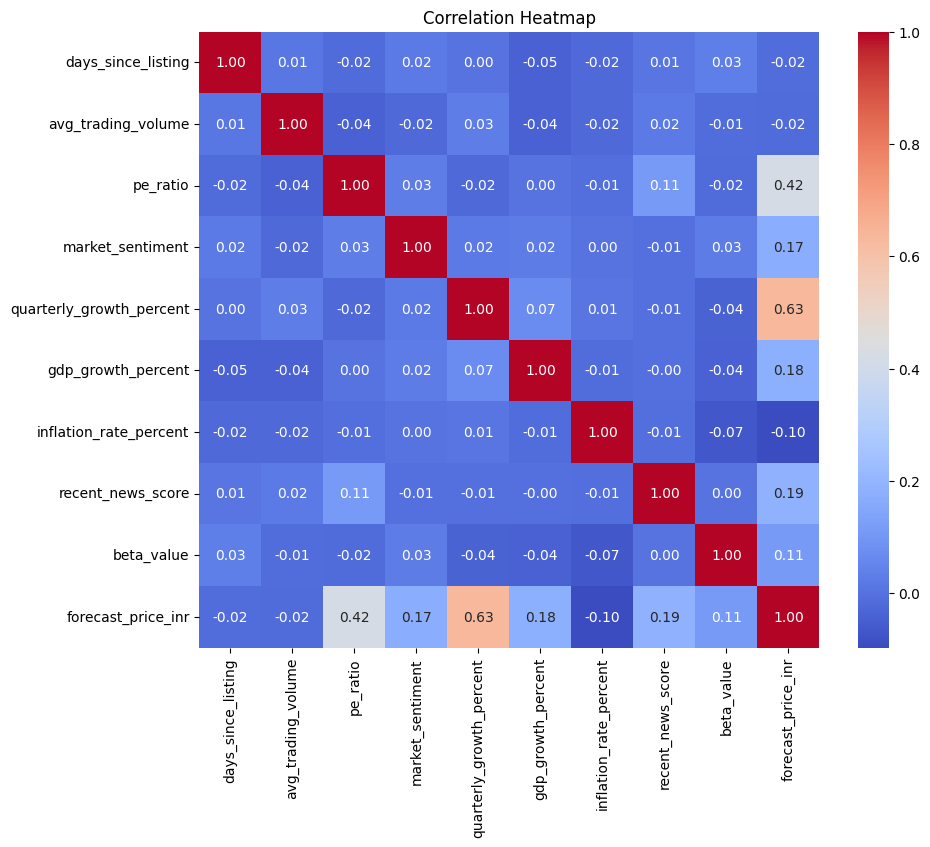

In [13]:
# Step 13: Correlation Heatmap

plt.figure(figsize=(10, 8))

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Heatmap")

plt.show()

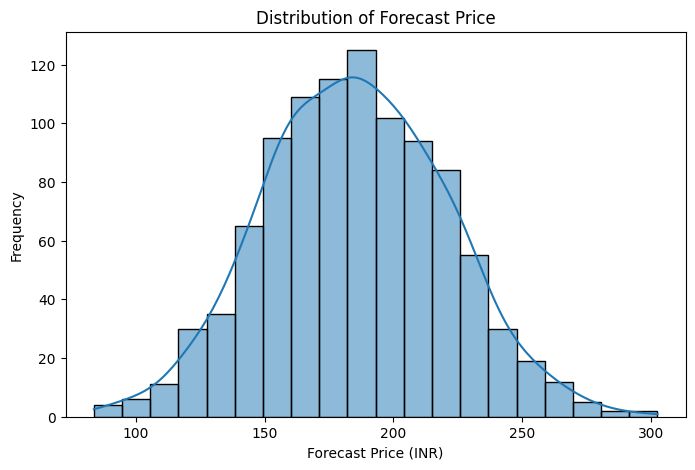

In [14]:
# Step 14: Distribution of Target Variable

plt.figure(figsize=(8, 5))

sns.histplot(df["forecast_price_inr"], bins=20, kde=True)

plt.title("Distribution of Forecast Price")
plt.xlabel("Forecast Price (INR)")
plt.ylabel("Frequency")

plt.show()

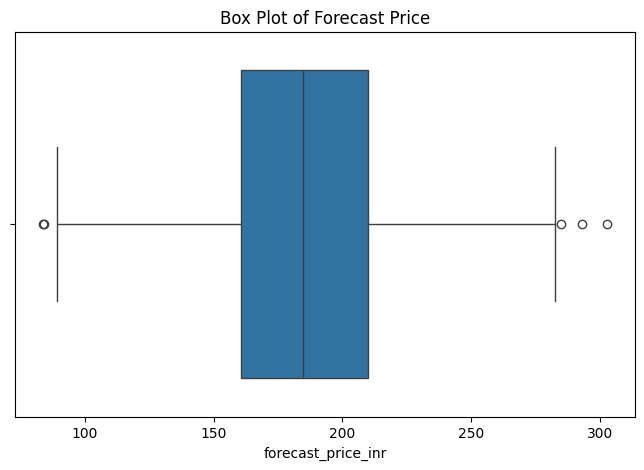

In [15]:
# Step 15: Box Plot of Target Variable

plt.figure(figsize=(8, 5))

sns.boxplot(x=df["forecast_price_inr"])

plt.title("Box Plot of Forecast Price")

plt.show()

# Data Preprocessing

In [16]:
# Step 16: Separate Features and Target Variable

X = df.drop("forecast_price_inr", axis=1)

y = df["forecast_price_inr"]

In [17]:
# Step 17: Display Features

X.head()

,stock_symbol,sector,days_since_listing,avg_trading_volume,pe_ratio,market_sentiment,quarterly_growth_percent,gdp_growth_percent,inflation_rate_percent,recent_news_score,beta_value
0,WIPRO,Banking,2906,586973.0,38.05,0.89,11.91,5.39,4.75,0.42,1.11
1,TCS,Energy,4866,1243868.0,25.78,-0.68,19.57,6.03,4.91,1.93,0.94
2,RELIANCE,Infrastructure,3686,1383937.0,12.54,0.48,8.73,8.67,6.18,-1.00,1.03
3,ICICIBANK,IT,4506,804741.0,17.57,-0.10,15.83,4.55,3.31,0.62,1.17
4,HDFCBANK,Infrastructure,4620,827764.0,13.57,-0.59,21.42,8.90,7.45,0.40,0.99


In [18]:
# Step 18: Display Target Variable

y.head()

,forecast_price_inr
0,204.33
1,189.90
2,163.79
3,184.69
4,184.91


In [19]:
# Step 19: Identify Categorical and Numerical Columns

categorical_columns = X.select_dtypes(include="object").columns

numerical_columns = X.select_dtypes(exclude="object").columns

print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
print(numerical_columns)

Categorical Columns:
Index(['stock_symbol', 'sector'], dtype='object')

Numerical Columns:
Index(['days_since_listing', 'avg_trading_volume', 'pe_ratio',
       'market_sentiment', 'quarterly_growth_percent', 'gdp_growth_percent',
       'inflation_rate_percent', 'recent_news_score', 'beta_value'],
      dtype='object')


In [20]:
# Step 20: Encode Categorical Columns

label_encoder = LabelEncoder()

for column in categorical_columns:
    X[column] = label_encoder.fit_transform(X[column])

In [21]:
# Step 21: Verify Encoded Features

X.head()

,stock_symbol,sector,days_since_listing,avg_trading_volume,pe_ratio,market_sentiment,quarterly_growth_percent,gdp_growth_percent,inflation_rate_percent,recent_news_score,beta_value
0,9,0,2906,586973.0,38.05,0.89,11.91,5.39,4.75,0.42,1.11
1,8,1,4866,1243868.0,25.78,-0.68,19.57,6.03,4.91,1.93,0.94
2,6,4,3686,1383937.0,12.54,0.48,8.73,8.67,6.18,-1.00,1.03
3,2,3,4506,804741.0,17.57,-0.10,15.83,4.55,3.31,0.62,1.17
4,1,4,4620,827764.0,13.57,-0.59,21.42,8.90,7.45,0.40,0.99


In [22]:
# Step 22: Split the Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [23]:
# Step 23: Check the Shape of Training and Testing Data

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (800, 11)
X_test : (200, 11)
y_train: (800,)
y_test : (200,)


# Feature Scaling

In [24]:
# Step 24: Scale Numerical Features

scaler = StandardScaler()

X_train[numerical_columns] = scaler.fit_transform(X_train[numerical_columns])

X_test[numerical_columns] = scaler.transform(X_test[numerical_columns])

In [25]:
# Step 25: Verify Scaled Features

X_train.head()

,stock_symbol,sector,days_since_listing,avg_trading_volume,pe_ratio,market_sentiment,quarterly_growth_percent,gdp_growth_percent,inflation_rate_percent,recent_news_score,beta_value
29,9,4,-0.796329,-0.956924,0.603377,1.734255,0.108343,0.099852,0.419226,-0.929946,-0.098597
535,8,0,-1.381879,-0.623921,1.252724,1.628852,-1.065199,1.069549,0.919431,0.735976,0.942528
695,0,2,-1.165212,-0.700752,-0.982646,-0.127867,0.246765,0.312712,-1.185599,0.879736,-0.049020
557,0,2,-1.596489,1.550368,-0.099908,0.469417,0.994592,1.223281,1.183428,0.558391,0.298022
836,4,1,-1.236520,-0.166290,-0.856096,0.943731,0.324246,0.986770,1.093113,-1.445790,0.496332


# Model Building

In [26]:
# Step 26: Train the Linear Regression Model

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

LinearRegression()

In [27]:
# Step 27: Predict Using Linear Regression

linear_predictions = linear_model.predict(X_test)

In [28]:
# Step 28: Evaluate Linear Regression Model

linear_mae = mean_absolute_error(y_test, linear_predictions)

linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))

linear_r2 = r2_score(y_test, linear_predictions)

print("MAE :", linear_mae)
print("RMSE:", linear_rmse)
print("R² Score:", linear_r2)

MAE : 17.219329989815215
RMSE: 21.166091184670936
R² Score: 0.6750490886976939


In [29]:
# Step 29: Train the Decision Tree Model

decision_tree_model = DecisionTreeRegressor(random_state=42)

decision_tree_model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [30]:
# Step 30: Predict and Evaluate Decision Tree Model

decision_tree_predictions = decision_tree_model.predict(X_test)

decision_tree_mae = mean_absolute_error(y_test, decision_tree_predictions)

decision_tree_rmse = np.sqrt(mean_squared_error(y_test, decision_tree_predictions))

decision_tree_r2 = r2_score(y_test, decision_tree_predictions)

print("MAE :", decision_tree_mae)
print("RMSE:", decision_tree_rmse)
print("R² Score:", decision_tree_r2)

MAE : 25.66205
RMSE: 32.2003429096648
R² Score: 0.24793145126442262


In [31]:
# Step 31: Train the Random Forest Model

random_forest_model = RandomForestRegressor(random_state=42)

random_forest_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [32]:
# Step 32: Predict and Evaluate the Random Forest Model

random_forest_predictions = random_forest_model.predict(X_test)

random_forest_mae = mean_absolute_error(y_test, random_forest_predictions)

random_forest_rmse = np.sqrt(mean_squared_error(y_test, random_forest_predictions))

random_forest_r2 = r2_score(y_test, random_forest_predictions)

print("MAE :", random_forest_mae)
print("RMSE:", random_forest_rmse)
print("R² Score:", random_forest_r2)

MAE : 18.994017499999995
RMSE: 23.62076530098358
R² Score: 0.5953082391990236


In [33]:
# Step 33: Train the Gradient Boosting Model

gradient_boosting_model = GradientBoostingRegressor(random_state=42)

gradient_boosting_model.fit(X_train, y_train)

GradientBoostingRegressor(random_state=42)

In [34]:
# Step 34: Predict and Evaluate the Gradient Boosting Model

gradient_boosting_predictions = gradient_boosting_model.predict(X_test)

gradient_boosting_mae = mean_absolute_error(y_test, gradient_boosting_predictions)

gradient_boosting_rmse = np.sqrt(mean_squared_error(y_test, gradient_boosting_predictions))

gradient_boosting_r2 = r2_score(y_test, gradient_boosting_predictions)

print("MAE :", gradient_boosting_mae)
print("RMSE:", gradient_boosting_rmse)
print("R² Score:", gradient_boosting_r2)

MAE : 18.592363795633077
RMSE: 23.01338105187275
R² Score: 0.6158531372499687


# Model Comparison

In [35]:
# Step 35: Compare Model Performance

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        linear_mae,
        decision_tree_mae,
        random_forest_mae,
        gradient_boosting_mae
    ],
    "RMSE": [
        linear_rmse,
        decision_tree_rmse,
        random_forest_rmse,
        gradient_boosting_rmse
    ],
    "R2 Score": [
        linear_r2,
        decision_tree_r2,
        random_forest_r2,
        gradient_boosting_r2
    ]
})

model_comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,17.219330,21.166091,0.675049
1,Decision Tree,25.662050,32.200343,0.247931
2,Random Forest,18.994017,23.620765,0.595308
3,Gradient Boosting,18.592364,23.013381,0.615853


In [36]:
# Step 36: Identify the Best Model

best_model = model_comparison.loc[model_comparison["R2 Score"].idxmax()]

best_model

,0
Model,Linear Regression
MAE,17.21933
RMSE,21.166091
R2 Score,0.675049


# Model Optimization

In [37]:
# Step 37: Import GridSearchCV

from sklearn.model_selection import GridSearchCV


In [38]:
# Step 38: Define Random Forest Hyperparameters

parameters = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

In [39]:
# Step 39: Perform Hyperparameter Tuning

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=parameters,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='r2')

In [40]:
# Step 40: Display Best Parameters

grid_search.best_params_

{'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}

In [41]:
# Step 41: Train the Optimized Random Forest Model

optimized_random_forest = RandomForestRegressor(
    max_depth=None,
    min_samples_split=5,
    n_estimators=200,
    random_state=42
)

optimized_random_forest.fit(X_train, y_train)

RandomForestRegressor(min_samples_split=5, n_estimators=200, random_state=42)

In [42]:
# Step 42: Evaluate the Optimized Random Forest Model

optimized_predictions = optimized_random_forest.predict(X_test)

optimized_mae = mean_absolute_error(y_test, optimized_predictions)

optimized_rmse = np.sqrt(mean_squared_error(y_test, optimized_predictions))

optimized_r2 = r2_score(y_test, optimized_predictions)

print("MAE :", optimized_mae)
print("RMSE:", optimized_rmse)
print("R² Score:", optimized_r2)

MAE : 18.95300485831738
RMSE: 23.588617453855207
R² Score: 0.5964090600585382


# Cross Validation

In [43]:
# Step 43: Import Cross Validation

from sklearn.model_selection import cross_val_score

In [44]:
# Step 44: Perform 5-Fold Cross Validation

cross_validation_scores = cross_val_score(
    linear_model,
    X,
    y,
    cv=5,
    scoring="r2"
)

In [45]:
# Step 45: Display Cross Validation Results

print("Cross Validation Scores:")
print(cross_validation_scores)

print("\nAverage R² Score:")
print(cross_validation_scores.mean())

Cross Validation Scores:
[0.67517288 0.63648203 0.70023298 0.67198986 0.65350878]

Average R² Score:
0.6674773083892962


# Feature Importance

In [46]:
# Step 46: Calculate Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": optimized_random_forest.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
6,quarterly_growth_percent,0.449662
4,pe_ratio,0.244038
5,market_sentiment,0.051063
7,gdp_growth_percent,0.048434
10,beta_value,0.044487
9,recent_news_score,0.039685
3,avg_trading_volume,0.034552
8,inflation_rate_percent,0.034264
2,days_since_listing,0.025541
0,stock_symbol,0.017605


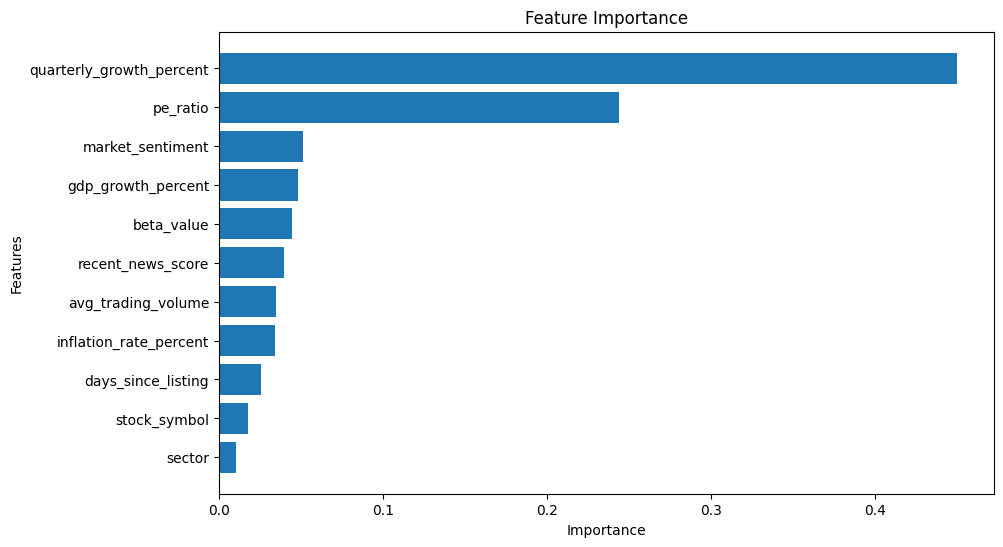

In [47]:
# Step 47: Visualize Feature Importance

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Feature Importance")

plt.gca().invert_yaxis()

plt.show()

# Actual vs Predicted Values

In [48]:
# Step 48: Predict Using the Best Model

linear_predictions = linear_model.predict(X_test)

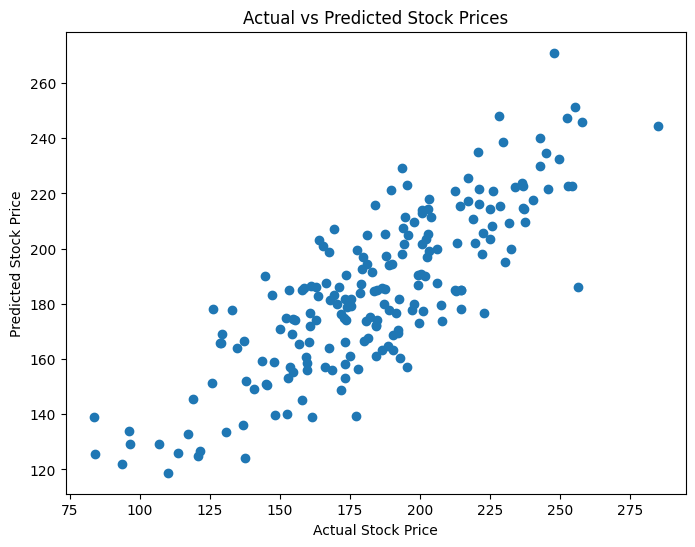

In [49]:
# Step 49: Plot Actual vs Predicted Values

plt.figure(figsize=(8, 6))

plt.scatter(y_test, linear_predictions)

plt.xlabel("Actual Stock Price")
plt.ylabel("Predicted Stock Price")
plt.title("Actual vs Predicted Stock Prices")

plt.show()

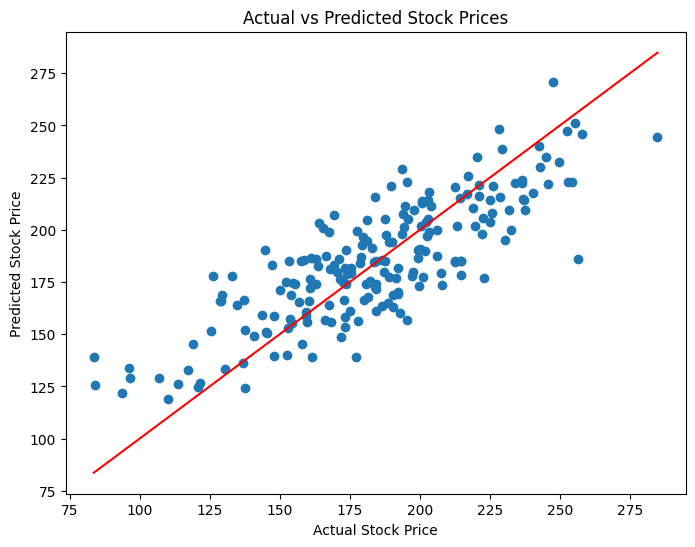

In [50]:
# Step 50: Plot the Ideal Prediction Line

plt.figure(figsize=(8, 6))

plt.scatter(y_test, linear_predictions)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.xlabel("Actual Stock Price")
plt.ylabel("Predicted Stock Price")
plt.title("Actual vs Predicted Stock Prices")

plt.show()

# Residual Analysis

In [51]:
# Step 51: Calculate Residuals

residuals = y_test - linear_predictions

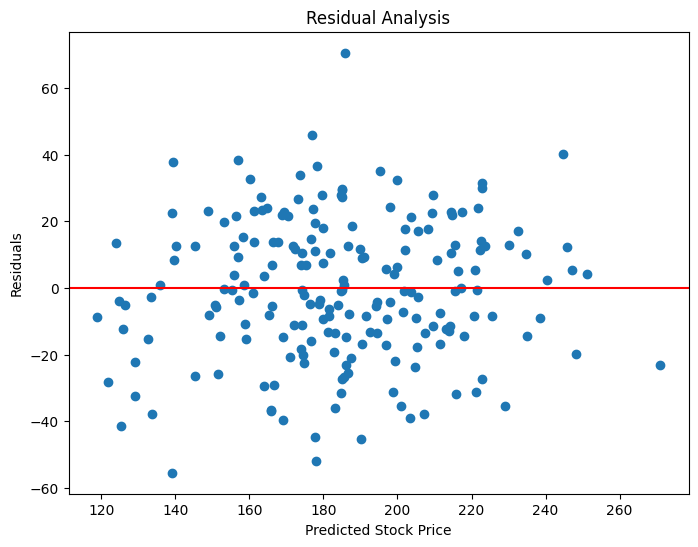

In [52]:
# Step 52: Plot Residuals

plt.figure(figsize=(8, 6))

plt.scatter(linear_predictions, residuals)

plt.axhline(y=0, color="red")

plt.xlabel("Predicted Stock Price")
plt.ylabel("Residuals")
plt.title("Residual Analysis")

plt.show()

# Save the Best Model

In [53]:
# Step 53: Save the Best Model

import joblib

joblib.dump(linear_model, "stock_price_prediction_model.pkl")

print("Model saved successfully.")

Model saved successfully.


# Predict on New Data

In [54]:
# Step 54: Create a New Sample

new_company = pd.DataFrame({
    "stock_symbol": [0],
    "sector": [0],
    "days_since_listing": [3000],
    "avg_trading_volume": [1000000],
    "pe_ratio": [25],
    "market_sentiment": [0.5],
    "quarterly_growth_percent": [15],
    "gdp_growth_percent": [6],
    "inflation_rate_percent": [5],
    "recent_news_score": [0.8],
    "beta_value": [1.1]
})

In [55]:
# Step 55: Scale Numerical Features and Predict

new_company_scaled = new_company.copy()

new_company_scaled[numerical_columns] = scaler.transform(
    new_company_scaled[numerical_columns]
)

predicted_price = linear_model.predict(new_company_scaled)

print("Predicted Stock Price (INR):", round(predicted_price[0], 2))

Predicted Stock Price (INR): 204.68
